# WFP2 – Data Inspection

In diesem Notebook wird der klinische RA-MAP-Datensatz zunächst untersucht.

Ziel ist es, die Datengrundlage für das spätere Pilotexperiment zur Remissionsvorhersage und für die DAS28-Regression zu prüfen.

Untersucht werden insbesondere:
- Anzahl der Patient:innen und Merkmale
- verfügbare DAS28-Zeitpunkte
- fehlende Werte
- Remission nach 12 Monaten
- Verteilung wichtiger klinischer Merkmale
- mögliche Baseline- und longitudinale Feature-Sets

In [1]:
import pandas as pd

df = pd.read_csv("../../datasets_final/Clinical_Clean_Merged.csv")

print("Shape:", df.shape)

df.head()

Shape: (275, 73)


,Patient_ID,Digest,ACPA.POSITIVE,RHUEMATOID.FACTOR,DAS28.0M,DAS28.3M,DAS28.6M,DAS28.9M,DAS28.12M,DAS28.18M,...,intraarticular_count,intramuscular_count,first_injection,last_injection,med_event_count,unique_medications,total_dose_y,mean_dose_y,first_med_date,last_med_date
0,TAC1000,B1895B6B8F7B325B977C180A25C74D079EFB5EB306693D...,1.0,1.0,7.27,1.91,2.13,1.14,1.54,1.13,...,NaN,NaN,NaN,NaN,18.0,3.0,1350.0,75.000000,2013-03-18,2013-05-02
1,TAC1001,59749E6B6785A9983100DA76AB0AE9484B52B2422AB362...,1.0,1.0,7.83,5.37,3.59,2.73,2.56,2.68,...,1.0,2.0,2013-02-05 00:00:00.000000000,2013-06-02 00:00:00.000000000,21.0,4.0,1480.0,70.476190,2013-02-05,2014-09-05
2,TAC1002,9C459B98832CB4E81C90B843BF7A7925D5E01A1A306586...,1.0,1.0,3.43,0.77,0.49,0.97,2.34,0.51,...,1.0,1.0,2013-08-05 00:00:00.000000000,2013-08-05 00:00:00.000000000,12.0,2.0,7200.0,600.000000,2013-05-29,2013-08-05
3,TAC1003,308098EB685FC45FA0CA61C88D25D810E16C9DADBBA77C...,1.0,1.0,5.76,3.59,2.91,2.88,2.01,2.62,...,0.0,1.0,2013-07-06 00:00:00.000000000,2013-07-06 00:00:00.000000000,18.0,3.0,2350.0,130.555556,2013-04-12,2014-12-05
4,TAC1004,3A9C04CAA9BBAAE16A20614D827FA3B55AA09C94F69284...,1.0,1.0,6.52,2.13,1.47,1.75,3.27,2.02,...,NaN,NaN,NaN,NaN,15.0,3.0,1122.5,74.833333,2013-09-13,2014-08-08


## Prüfung der Patient:innen-IDs

Es wird geprüft, ob jede Zeile einem eindeutigen Patienten bzw. einer eindeutigen Patientin entspricht und ob doppelte Patient_IDs vorhanden sind.

In [2]:
print("Anzahl Zeilen:", len(df))
print("Eindeutige Patient_IDs:", df["Patient_ID"].nunique())
print("Doppelte Patient_IDs:", df["Patient_ID"].duplicated().sum())

Anzahl Zeilen: 275
Eindeutige Patient_IDs: 275
Doppelte Patient_IDs: 0


## Verfügbare DAS28-Zeitpunkte

Es wird geprüft, welche DAS28-Messzeitpunkte im Datensatz vorhanden sind und wie viele Werte pro Zeitpunkt fehlen.

In [3]:
das28_columns = [
    "DAS28.0M",
    "DAS28.3M",
    "DAS28.6M",
    "DAS28.9M",
    "DAS28.12M",
    "DAS28.18M"
]

print("Vorhandene DAS28-Zeitpunkte:")
for col in das28_columns:
    print(
        f"{col}: "
        f"{df[col].notna().sum()} vorhanden, "
        f"{df[col].isna().sum()} fehlend"
    )

Vorhandene DAS28-Zeitpunkte:
DAS28.0M: 275 vorhanden, 0 fehlend
DAS28.3M: 275 vorhanden, 0 fehlend
DAS28.6M: 275 vorhanden, 0 fehlend
DAS28.9M: 275 vorhanden, 0 fehlend
DAS28.12M: 275 vorhanden, 0 fehlend
DAS28.18M: 275 vorhanden, 0 fehlend


## Fehlende Werte in den geplanten klinischen Merkmalen

Nun wird geprüft, wie vollständig die klinischen Variablen sind, die später für die Baseline- und longitudinalen Modelle verwendet werden könnten.

In [4]:
candidate_features = [
    "DAS28.0M",
    "DAS28.3M",
    "DAS28.6M",
    "CRP.0M",
    "CRP.6M",
    "ESR.0M",
    "HAQ.0M",
    "HAQ.6M",
    "AGE",
    "GENDER",
    "RHUEMATOID.FACTOR",
    "ACPA.POSITIVE"
]

missing_summary = pd.DataFrame({
    "Vorhanden": df[candidate_features].notna().sum(),
    "Fehlend": df[candidate_features].isna().sum(),
    "Fehlend_%": df[candidate_features].isna().mean() * 100
})

missing_summary

,Vorhanden,Fehlend,Fehlend_%
DAS28.0M,275,0,0.000000
DAS28.3M,275,0,0.000000
DAS28.6M,275,0,0.000000
CRP.0M,275,0,0.000000
CRP.6M,275,0,0.000000
ESR.0M,275,0,0.000000
HAQ.0M,275,0,0.000000
HAQ.6M,275,0,0.000000
AGE,275,0,0.000000
GENDER,271,4,1.454545


## Ausprägungen kategorialer Merkmale

Die möglichen Werte von Geschlecht, Rheumafaktor und ACPA werden geprüft.
Dabei werden auch fehlende Werte berücksichtigt.

In [5]:
categorical_features = [
    "GENDER",
    "RHUEMATOID.FACTOR",
    "ACPA.POSITIVE"
]

for col in categorical_features:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


GENDER:
GENDER
0.0    196
1.0     75
NaN      4
Name: count, dtype: int64

RHUEMATOID.FACTOR:
RHUEMATOID.FACTOR
1.0    247
0.0     25
NaN      3
Name: count, dtype: int64

ACPA.POSITIVE:
ACPA.POSITIVE
1.0    232
0.0     39
NaN      4
Name: count, dtype: int64


## Remission nach 12 Monaten

Für das Pilotexperiment wird eine binäre Zielvariable für die Remission nach 12 Monaten erstellt.

Eine Remission wird definiert als:

- DAS28 < 2.6 → Remission
- DAS28 ≥ 2.6 → keine Remission

In [6]:
df["remission_12m"] = (df["DAS28.12M"] < 2.6).astype(int)

print("Remission nach 12 Monaten:")
print(df["remission_12m"].value_counts())

print("\nProzentuale Verteilung:")
print(df["remission_12m"].value_counts(normalize=True) * 100)

Remission nach 12 Monaten:
remission_12m
0    204
1     71
Name: count, dtype: int64

Prozentuale Verteilung:
remission_12m
0    74.181818
1    25.818182
Name: proportion, dtype: float64


## Verteilung der Remissionsklassen

Die Zielvariable ist unausgeglichen. Etwa ein Viertel der Patient:innen befindet sich nach 12 Monaten in Remission, während etwa drei Viertel keine Remission erreichen.

Diese Verteilung wird bei der späteren Cross-Validation berücksichtigt.

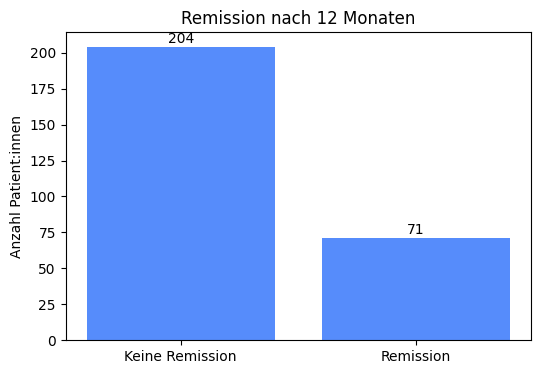

In [7]:
import matplotlib.pyplot as plt

counts = df["remission_12m"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Keine Remission", "Remission"], counts.values)

plt.title("Remission nach 12 Monaten")
plt.ylabel("Anzahl Patient:innen")

for i, value in enumerate(counts.values):
    plt.text(i, value + 3, str(value), ha="center")

plt.show()

## Alter und Geschlecht

Als weitere grundlegende Merkmale werden Alter und Geschlecht der Patient:innen untersucht.

Beim Geschlecht wird zunächst nur die vorhandene 0/1-Codierung betrachtet. Die genaue Bedeutung der Codes muss noch anhand der Datendokumentation verifiziert werden.

In [8]:
print("Alter:")
print(df["AGE"].describe())

print("\nFehlende Alterswerte:", df["AGE"].isna().sum())

Alter:
count    275.000000
mean      53.149091
std       15.043839
min       20.000000
25%       43.000000
50%       53.000000
75%       65.000000
max       84.000000
Name: AGE, dtype: float64

Fehlende Alterswerte: 0


In [9]:
gender_counts = df["GENDER"].value_counts(dropna=False)
gender_percent = df["GENDER"].value_counts(normalize=True, dropna=False) * 100

gender_summary = pd.DataFrame({
    "Anzahl": gender_counts,
    "Prozent": gender_percent
})

gender_summary

,Anzahl,Prozent
GENDER,,
0.0,196,71.272727
1.0,75,27.272727
NaN,4,1.454545


### Zwischenfazit

- Das Alter ist für alle 275 Patient:innen vollständig vorhanden.
- Das Durchschnittsalter beträgt ca. 53 Jahre.
- Die Altersverteilung reicht von 20 bis 84 Jahren.
- Beim Merkmal GENDER liegen 4 fehlende Werte vor.
- Die Geschlechtsvariable ist numerisch als 0/1 codiert; die genaue Bedeutung der Codes muss noch verifiziert werden.

## Definition der Merkmalsräume

Die Auswahl der klinischen Merkmale orientiert sich an publizierten Arbeiten zu Prädiktoren von Therapieansprechen und Remission bei rheumatoider Arthritis.

Untersucht werden zwei Merkmalsräume:

- **Baseline-Merkmalsraum:** ausschließlich klinische Informationen zum Ausgangszeitpunkt.
- **Longitudinaler Merkmalsraum:** Baseline-Merkmale plus frühe Verlaufswerte aus den ersten Monaten.

Ziel ist es zu prüfen, ob frühe longitudinale Informationen einen zusätzlichen Vorhersagewert gegenüber reinen Baseline-Daten liefern.

In [10]:
baseline_features = [
    "DAS28.0M",
    "CRP.0M",
    "ESR.0M",
    "HAQ.0M",
    "AGE",
    "GENDER",
    "RHUEMATOID.FACTOR",
    "ACPA.POSITIVE"
]

longitudinal_features = baseline_features + [
    "DAS28.3M",
    "DAS28.6M",
    "CRP.6M",
    "HAQ.6M"
]

print("Baseline-Features:")
for feature in baseline_features:
    print("-", feature)

print("\nLongitudinale Features:")
for feature in longitudinal_features:
    print("-", feature)

Baseline-Features:
- DAS28.0M
- CRP.0M
- ESR.0M
- HAQ.0M
- AGE
- GENDER
- RHUEMATOID.FACTOR
- ACPA.POSITIVE

Longitudinale Features:
- DAS28.0M
- CRP.0M
- ESR.0M
- HAQ.0M
- AGE
- GENDER
- RHUEMATOID.FACTOR
- ACPA.POSITIVE
- DAS28.3M
- DAS28.6M
- CRP.6M
- HAQ.6M


## Vollständigkeit der Merkmalsräume

Zum Abschluss wird geprüft, wie viele fehlende Werte in den definierten Baseline- und longitudinalen Merkmalsräumen vorhanden sind.

Fehlende Werte werden später innerhalb der Machine-Learning-Pipeline behandelt und nicht vorab aus dem gesamten Datensatz entfernt.

In [11]:
print("Baseline-Merkmalsraum:")
print(df[baseline_features].isna().sum())

print("\nAnzahl Patient:innen mit mindestens einem fehlenden Baseline-Wert:")
print(df[baseline_features].isna().any(axis=1).sum())


print("\nLongitudinaler Merkmalsraum:")
print(df[longitudinal_features].isna().sum())

print("\nAnzahl Patient:innen mit mindestens einem fehlenden longitudinalen Wert:")
print(df[longitudinal_features].isna().any(axis=1).sum())

Baseline-Merkmalsraum:
DAS28.0M             0
CRP.0M               0
ESR.0M               0
HAQ.0M               0
AGE                  0
GENDER               4
RHUEMATOID.FACTOR    3
ACPA.POSITIVE        4
dtype: int64

Anzahl Patient:innen mit mindestens einem fehlenden Baseline-Wert:
5

Longitudinaler Merkmalsraum:
DAS28.0M             0
CRP.0M               0
ESR.0M               0
HAQ.0M               0
AGE                  0
GENDER               4
RHUEMATOID.FACTOR    3
ACPA.POSITIVE        4
DAS28.3M             0
DAS28.6M             0
CRP.6M               0
HAQ.6M               0
dtype: int64

Anzahl Patient:innen mit mindestens einem fehlenden longitudinalen Wert:
5
